# Energy Transition & Electric Mobility in Portugal - EDA

**Phase 3: quick first look.** Deeper analysis (seasonality, source volatility,
price correlation, geographic patterns) continues in the next session.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df_ren = pd.read_csv(DATA_PROCESSED / "ren_daily_production.csv", parse_dates=["date"])
df_eredes = pd.read_csv(
    DATA_PROCESSED / "eredes_mobility_monthly.csv", parse_dates=["date"]
)

print(df_ren.shape, df_eredes.shape)
df_ren[
    ["renovavel_mwh", "nao_renovavel_mwh", "pct_renovavel", "pct_renovavel_com_import"]
].describe()

(1826, 22) (3336, 4)


,renovavel_mwh,nao_renovavel_mwh,pct_renovavel,pct_renovavel_com_import
count,1826.000000,1826.000000,1826.000000,1826.000000
mean,99332.024562,27150.692552,77.625192,61.074206
std,35005.602898,17560.684637,14.845118,16.343617
min,30848.950000,2006.050000,30.200000,19.600000
25%,73791.740000,15385.097500,69.000000,49.200000
50%,94123.145000,22689.340000,82.100000,60.300000
75%,122299.365000,36727.397500,87.700000,73.400000
max,215201.990000,82448.100000,98.700000,98.600000


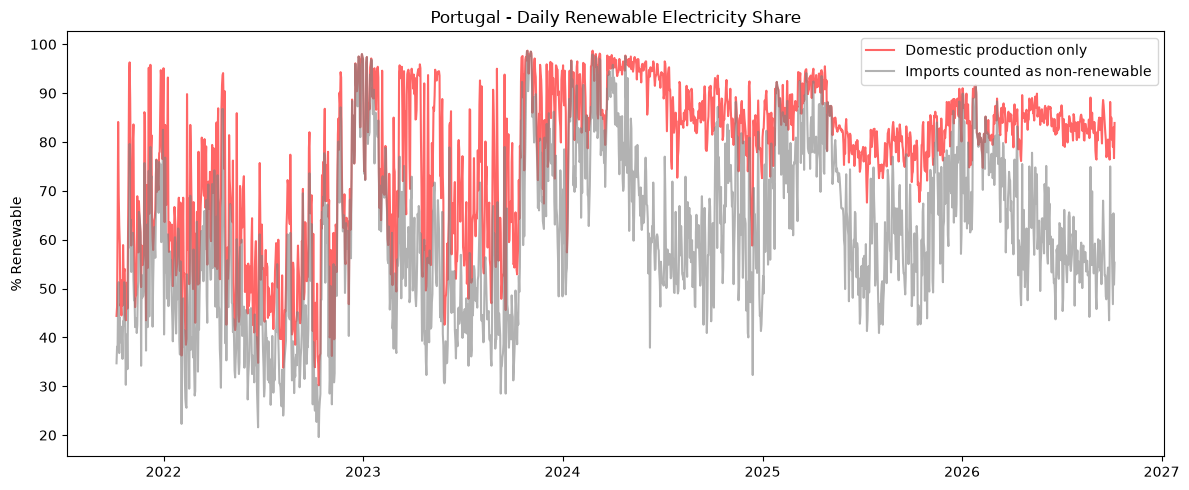

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    df_ren["date"],
    df_ren["pct_renovavel"],
    label="Domestic production only",
    color="red",
    alpha=0.6,
)
ax.plot(
    df_ren["date"],
    df_ren["pct_renovavel_com_import"],
    color="grey",
    label="Imports counted as non-renewable",
    alpha=0.6,
)
ax.set_ylabel("% Renewable")
ax.set_title("Portugal - Daily Renewable Electricity Share")
ax.legend()
plt.tight_layout()
plt.show()

## Smoothed renewable share chart

Daily values are noisy - applying a rolling average and adding light
year-boundary lines to make the trend and yearly comparison easier to read.
Testing both a 3-day and a 7-day (weekly) window to see which reads better.

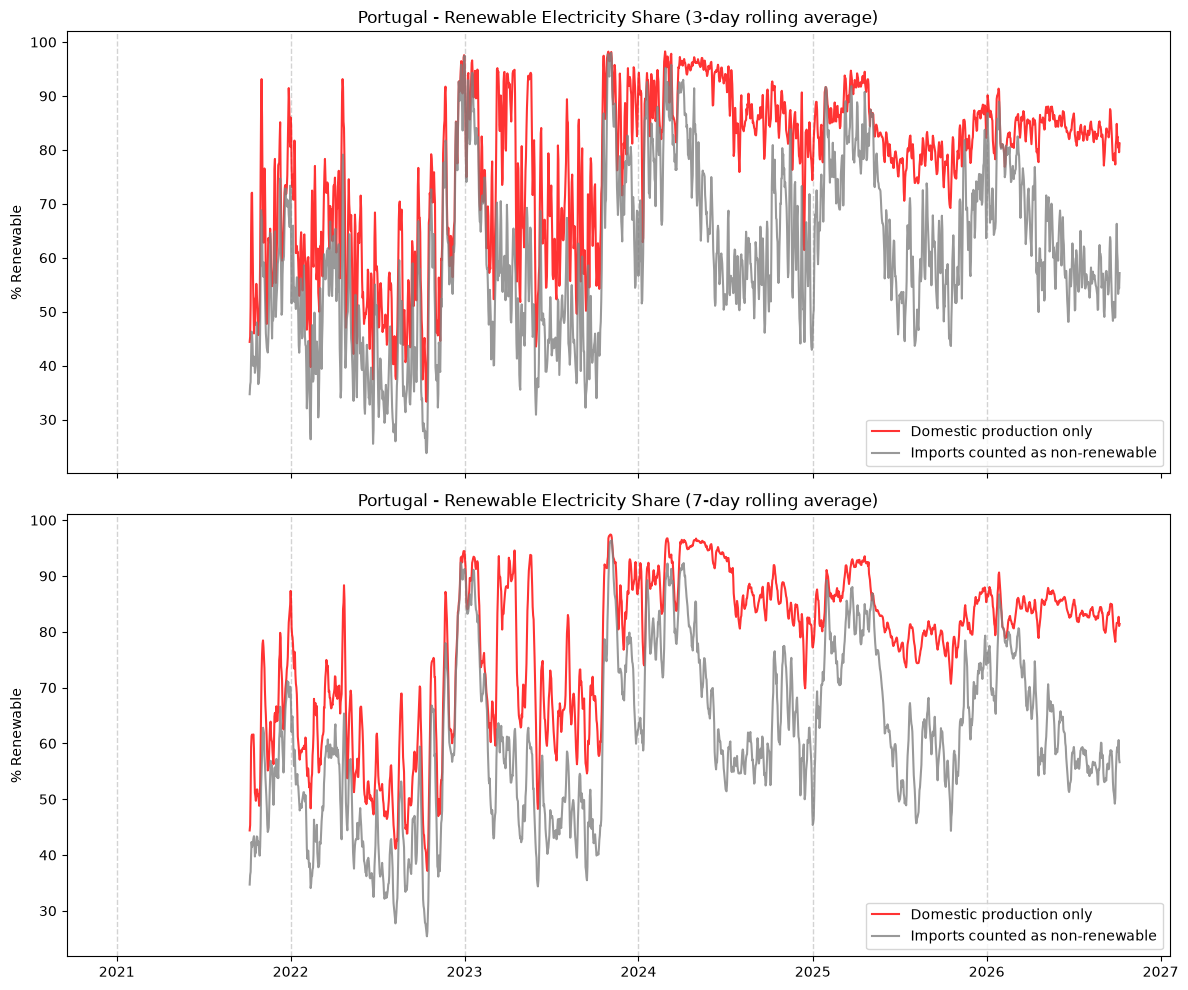

In [3]:
def plot_renewable_share(df, window_days, ax=None):
    # Time-based rolling window (not row-based) — correctly handles the
    # 2 missing days in the data without shifting the average
    df_indexed = df.set_index("date").sort_index()
    smoothed = (
        df_indexed[["pct_renovavel", "pct_renovavel_com_import"]]
        .rolling(f"{window_days}D")
        .mean()
    )

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        smoothed.index,
        smoothed["pct_renovavel"],
        label="Domestic production only",
        alpha=0.8,
        color="red",
    )
    ax.plot(
        smoothed.index,
        smoothed["pct_renovavel_com_import"],
        label="Imports counted as non-renewable",
        alpha=0.8,
        color="grey",
    )

    # Light vertical line at the start of each year present in the data
    for year in range(df["date"].dt.year.min(), df["date"].dt.year.max() + 1):
        ax.axvline(
            pd.Timestamp(f"{year}-01-01"),
            color="lightgray",
            linestyle="--",
            linewidth=1,
            zorder=0,
        )

    ax.set_ylabel("% Renewable")
    ax.set_title(
        f"Portugal - Renewable Electricity Share ({window_days}-day rolling average)"
    )
    ax.legend()
    return ax


fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
plot_renewable_share(df_ren, window_days=3, ax=axes[0])
plot_renewable_share(df_ren, window_days=7, ax=axes[1])
plt.tight_layout()
plt.show()

### Final version  of the graph

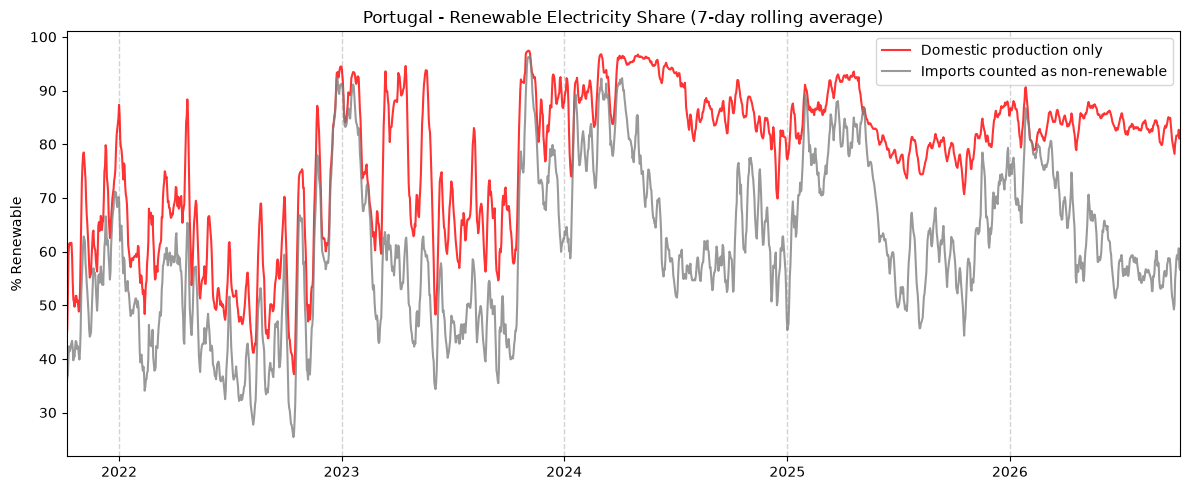

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_renewable_share(df_ren, window_days=7, ax=ax)
ax.set_xlim(
    df_ren["date"].min(), df_ren["date"].max()
)  # trim empty space before the first data point
plt.tight_layout()
plt.show()

## Renewable source volatility comparison

Coefficient of variation (std / mean) for each renewable source's daily
production - normalizes for scale, so sources with different typical output
levels can be compared fairly. Comparing all five before deciding whether
a deeper Wind vs. Solar analysis is actually warranted.

Wind       0.653
Hydro      0.620
Solar      0.594
Biomass    0.125
Wave         NaN
dtype: float64


C:\Users\joaof\AppData\Local\Temp\ipykernel_12524\2116542552.py:4: RuntimeWarning: invalid value encountered in scalar divide
  source: df_ren[source].std() / df_ren[source].mean() for source in RENEWABLE_SOURCES


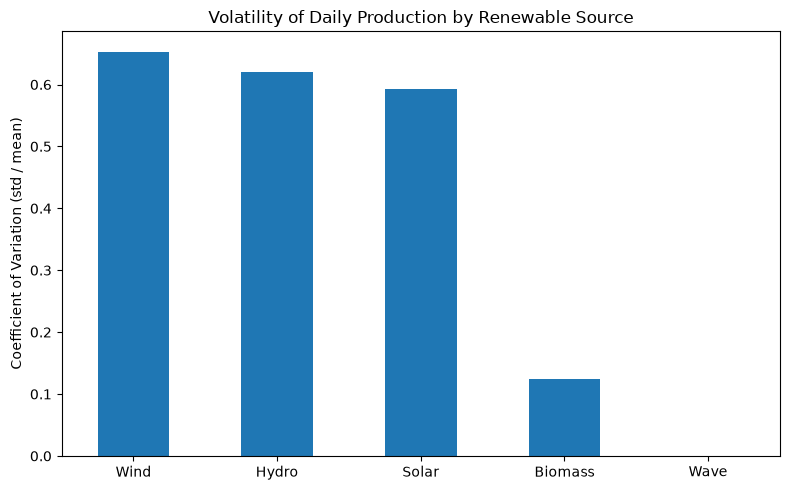

In [5]:
RENEWABLE_SOURCES = ["Hydro", "Solar", "Wind", "Biomass", "Wave"]

cv_by_source = {
    source: df_ren[source].std() / df_ren[source].mean() for source in RENEWABLE_SOURCES
}

cv_series = pd.Series(cv_by_source).sort_values(ascending=False)
print(cv_series.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
cv_series.plot(kind="bar", ax=ax)
ax.set_ylabel("Coefficient of Variation (std / mean)")
ax.set_title("Volatility of Daily Production by Renewable Source")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
print(df_ren["Wave"].describe())

count    1090.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: Wave, dtype: float64


## Seasonality: renewable share by month

Average % renewable per calendar month, across all years, to see which
months are typically high/low. Also broken down by year to check whether
the winter peaks are actually declining over time, as suspected from the
smoothed chart.

month
1     82.1
2     77.1
3     83.2
4     84.1
5     80.6
6     74.9
7     72.7
8     73.4
9     73.7
10    72.3
11    75.8
12    81.5
Name: pct_renovavel, dtype: float64


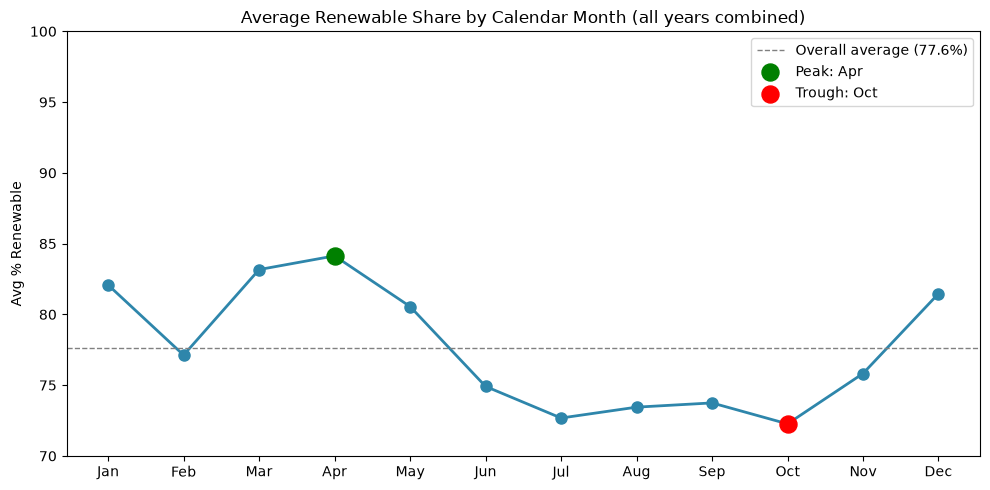

In [7]:
df_ren["month"] = df_ren["date"].dt.month
df_ren["year"] = df_ren["date"].dt.year

monthly_avg = df_ren.groupby("month")["pct_renovavel"].mean()
print(monthly_avg.round(1))

month_names = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    markersize=8,
    linewidth=2,
    color="#2E86AB",
)

overall_avg = monthly_avg.mean()
ax.axhline(
    overall_avg,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"Overall average ({overall_avg:.1f}%)",
)

peak_month = monthly_avg.idxmax()
trough_month = monthly_avg.idxmin()
ax.scatter(
    [peak_month],
    [monthly_avg[peak_month]],
    color="green",
    s=150,
    zorder=5,
    label=f"Peak: {month_names[peak_month - 1]}",
)
ax.scatter(
    [trough_month],
    [monthly_avg[trough_month]],
    color="red",
    s=150,
    zorder=5,
    label=f"Trough: {month_names[trough_month - 1]}",
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_ylabel("Avg % Renewable")
ax.set_title("Average Renewable Share by Calendar Month (all years combined)")
ax.legend()
ax.set_ylim(70, 100)
plt.tight_layout()
plt.show()

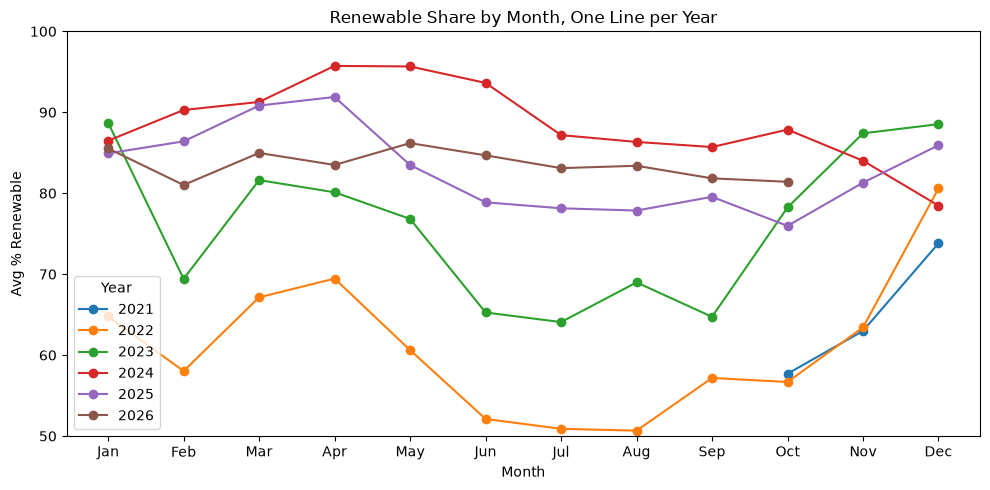

In [19]:
monthly_by_year = (
    df_ren.groupby(["year", "month"])["pct_renovavel"].mean().unstack(level=0)
)

fig, ax = plt.subplots(figsize=(10, 5))
monthly_by_year.plot(ax=ax, marker="o")
ax.set_xlabel("Month")
ax.set_ylabel("Avg % Renewable")
ax.set_title("Renewable Share by Month, One Line per Year")
ax.legend(title="Year")
ax.set_ylim(50, 100)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
plt.tight_layout()
plt.show()

## Hydro vs Wind vs Solar: which one drove the 2024->2025 dip?

Same monthly-by-year view as before, but per source, side by side.
Focus on Apr-Jun, where the total % renewable dip was clearest.

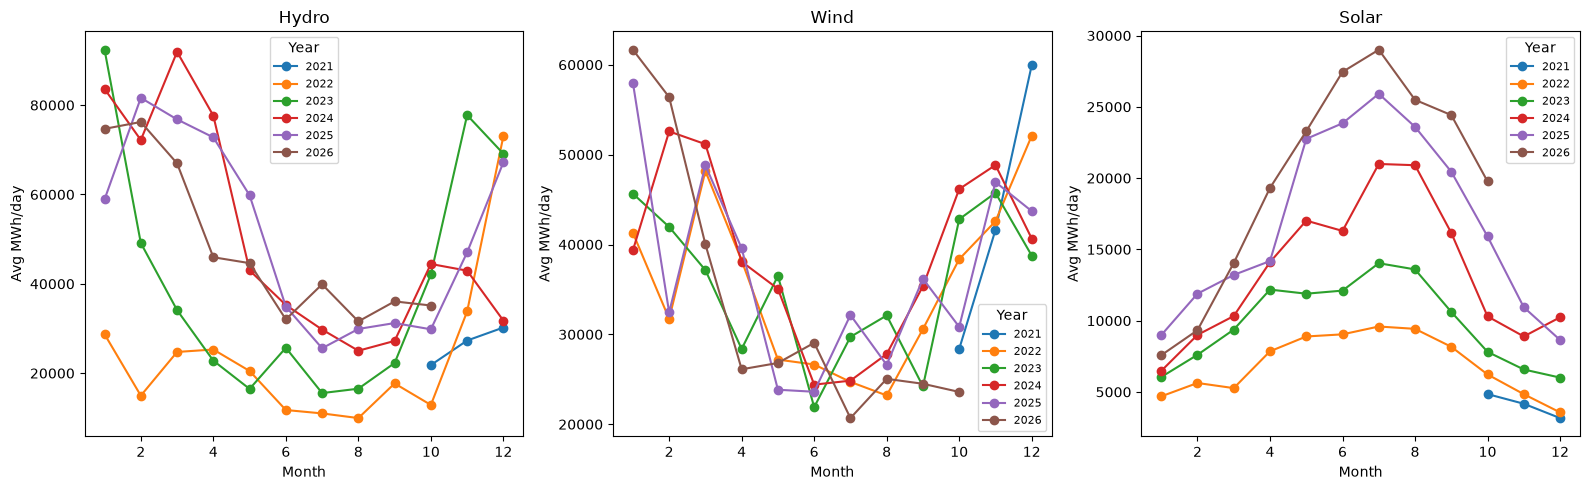

In [9]:
sources_to_check = ["Hydro", "Wind", "Solar"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)

for ax, source in zip(axes, sources_to_check):
    by_year = df_ren.groupby(["year", "month"])[source].mean().unstack(level=0)
    by_year.plot(ax=ax, marker="o")
    ax.set_title(source)
    ax.set_xlabel("Month")
    ax.set_ylabel("Avg MWh/day")
    ax.legend(title="Year", fontsize=8)

plt.tight_layout()
plt.show()

In [10]:
for source in sources_to_check:
    apr_jun = df_ren[df_ren["month"].isin([4, 5, 6])]
    by_year = apr_jun.groupby("year")[source].mean()

    if 2024 in by_year.index and 2025 in by_year.index:
        pct_change = (by_year[2025] - by_year[2024]) / by_year[2024] * 100
        print(
            f"{source}: 2024 avg = {by_year[2024]:.0f} MWh/day | 2025 avg = {by_year[2025]:.0f} MWh/day | change = {pct_change:+.1f}%"
        )

Hydro: 2024 avg = 51872 MWh/day | 2025 avg = 55876 MWh/day | change = +7.7%
Wind: 2024 avg = 32552 MWh/day | 2025 avg = 28954 MWh/day | change = -11.1%
Solar: 2024 avg = 15819 MWh/day | 2025 avg = 20287 MWh/day | change = +28.2%


In [11]:
non_renewable_sources = ["Natural Gas", "Other Thermal", "Coal"]

for source in non_renewable_sources:
    apr_jun = df_ren[df_ren["month"].isin([4, 5, 6])]
    by_year = apr_jun.groupby("year")[source].mean()

    if 2024 in by_year.index and 2025 in by_year.index:
        pct_change = (by_year[2025] - by_year[2024]) / by_year[2024] * 100
        print(
            f"{source}: 2024 avg = {by_year[2024]:.0f} MWh/day | 2025 avg = {by_year[2025]:.0f} MWh/day | change = {pct_change:+.1f}%"
        )

# Also check total demand, to see if this is simply "more electricity needed overall"
apr_jun = df_ren[df_ren["month"].isin([4, 5, 6])]
consumption_by_year = apr_jun.groupby("year")["Consumption"].mean()
print(
    f"\nConsumption: 2024 avg = {consumption_by_year[2024]:.0f} MWh/day | 2025 avg = {consumption_by_year[2025]:.0f} MWh/day | change = {(consumption_by_year[2025] - consumption_by_year[2024]) / consumption_by_year[2024] * 100:+.1f}%"
)

Natural Gas: 2024 avg = 4910 MWh/day | 2025 avg = 18604 MWh/day | change = +278.9%
Other Thermal: 2024 avg = 665 MWh/day | 2025 avg = 610 MWh/day | change = -8.2%
Coal: 2024 avg = 0 MWh/day | 2025 avg = 0 MWh/day | change = +nan%

Consumption: 2024 avg = 131400 MWh/day | 2025 avg = 133701 MWh/day | change = +1.8%


C:\Users\joaof\AppData\Local\Temp\ipykernel_12524\2578077382.py:8: RuntimeWarning: invalid value encountered in scalar divide
  pct_change = (by_year[2025] - by_year[2024]) / by_year[2024] * 100


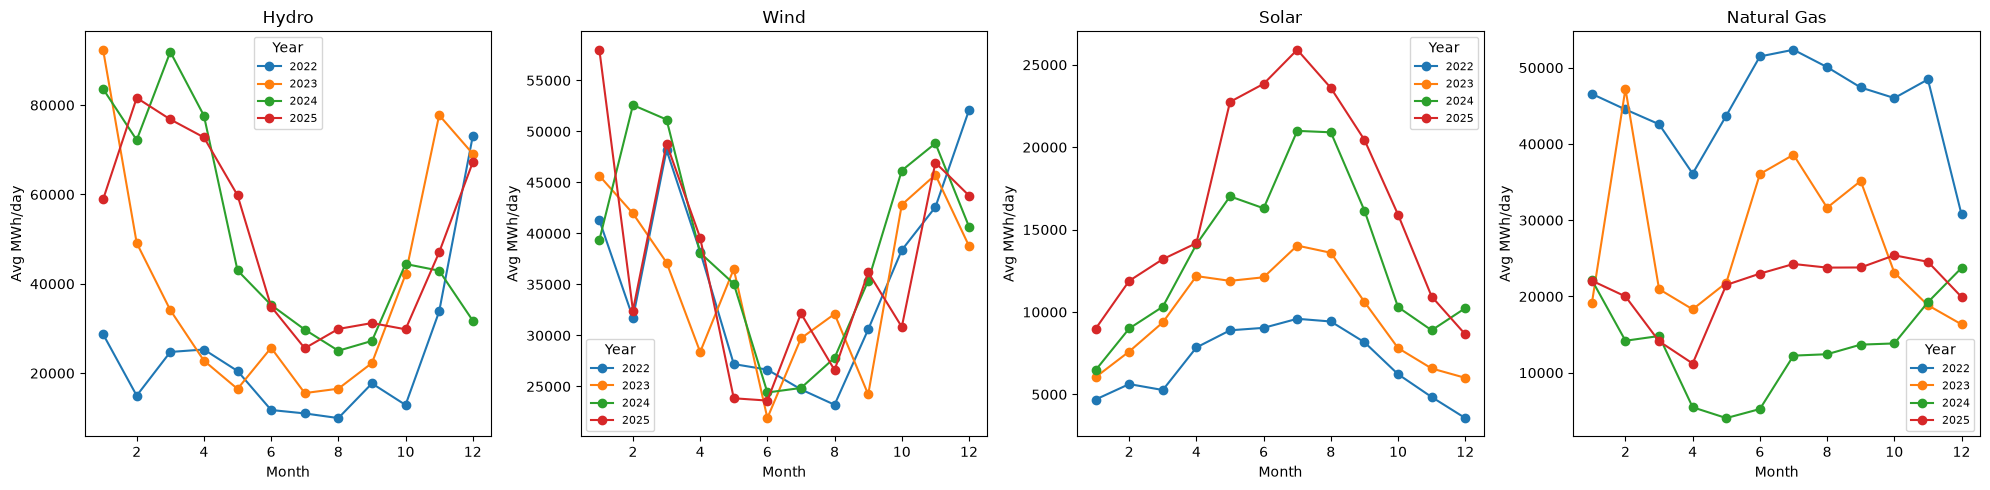

In [ ]:
years_to_compare = [2022, 2023, 2024, 2025]
sources_to_check = ["Hydro", "Wind", "Solar", "Natural Gas"]

df_filtered = df_ren[df_ren["year"].isin(years_to_compare)]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True)

for ax, source in zip(axes, sources_to_check):
    by_year = df_filtered.groupby(["year", "month"])[source].mean().unstack(level=0)
    by_year.plot(ax=ax, marker="o")
    ax.set_title(source)
    ax.set_xlabel("Month")
    ax.set_ylabel("Avg MWh/day")
    ax.legend(title="Year", fontsize=8)

plt.tight_layout()
plt.show()

# E-REDES Electric Mobility - Geographic EDA

Quick ranking first, then a proper choropleth map
by município.

In [13]:
top_concelhos = (
    df_eredes.groupby("concelho")["energia_mwh"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)
print(top_concelhos.round(1))

concelho
Lisboa                 26125.1
Sintra                  9417.8
Cascais                 9246.5
Oeiras                  9105.4
Porto                   7929.2
Loures                  7764.1
Vila Nova de Gaia       6934.5
Matosinhos              5547.5
Leiria                  4429.0
Odivelas                4361.7
Seixal                  4273.6
Amadora                 4188.3
Braga                   3898.9
Vila Franca de Xira     3778.3
Almada                  3769.8
Name: energia_mwh, dtype: float64


## Price vs production correlation

Testing the merit order effect: wind and solar have near-zero marginal
cost, so on days with high renewable output, expensive gas plants are
needed less, and market price tends to drop. Merging the production and
price tables by date to check whether this shows up in the data, plus
whether PT/ES market splits cluster on high-renewable days (possible
grid congestion when Portugal has a renewable surplus).

In [14]:
df_prices = pd.read_csv(
    DATA_PROCESSED / "ren_market_prices_daily.csv", parse_dates=["date"]
)
print(df_prices.shape)
df_prices.head()

(1727, 8)


,date,price_avg_PT,price_min_PT,price_max_PT,price_avg_ES,price_min_ES,price_max_ES,price_diverges
0,2021-10-07,288.53,249.08,319.03,288.53,249.08,319.03,False
1,2021-10-08,229.20,188.60,290.00,229.20,188.60,290.00,False
2,2021-10-09,226.21,176.92,254.45,226.21,176.92,254.45,False
3,2021-10-10,175.91,135.07,251.60,175.64,135.07,251.60,False
4,2021-10-11,184.48,125.01,241.27,184.48,125.01,241.27,False


In [15]:
df_merged = df_ren.merge(df_prices, on="date", how="inner")
print(f"Merged rows: {len(df_merged)}")

Merged rows: 1727


In [16]:
correlation_cols = [
    "pct_renovavel",
    "pct_renovavel_com_import",
    "Wind",
    "Solar",
    "Hydro",
]
correlations = (
    df_merged[correlation_cols + ["price_avg_PT"]]
    .corr()["price_avg_PT"]
    .drop("price_avg_PT")
)
print(correlations.round(3))

pct_renovavel              -0.671
pct_renovavel_com_import   -0.526
Wind                       -0.192
Solar                      -0.389
Hydro                      -0.373
Name: price_avg_PT, dtype: float64


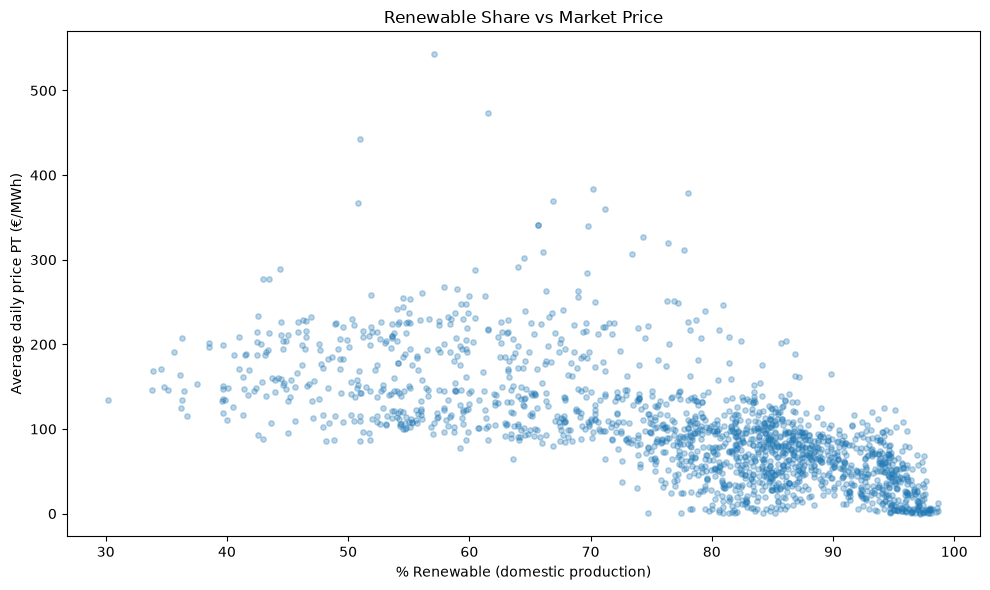

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_merged["pct_renovavel"], df_merged["price_avg_PT"], alpha=0.3, s=15)
ax.set_xlabel("% Renewable (domestic production)")
ax.set_ylabel("Average daily price PT (€/MWh)")
ax.set_title("Renewable Share vs Market Price")
plt.tight_layout()
plt.show()

In [18]:
split_renewable = df_merged.groupby("price_diverges")["pct_renovavel"].mean()
print(split_renewable.round(1))

price_diverges
False    76.8
True     80.3
Name: pct_renovavel, dtype: float64


## Next: 04_Predictive_Model.ipynb